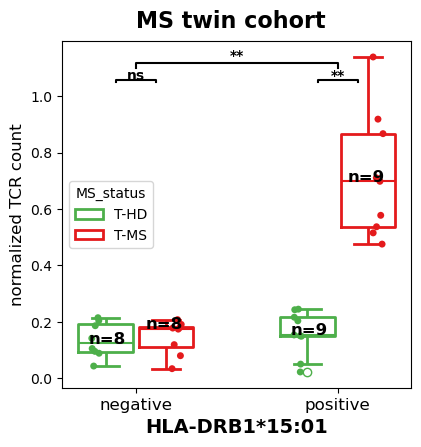

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon, mannwhitneyu

hla_df = pd.read_csv('../../meta_data_new_db/twins_hla_typing.tsv', sep='\t')
hla_df = hla_df[['subject_id', 'HLA_DRB1*15:01']]
hla_df.columns=['subject_id', 'HLA']
df = pd.read_csv('./tables/twins.tsv', sep='\t')
df['normalized_seqs'] = df.apply(lambda x: (x.unique_specific_sequences / x.unique_productive_rearrangment)* 10000, axis=1)
# df['normalized_seqs'] = np.log1p(df.normalized_seqs)

fig_df = df.merge(hla_df, on ='subject_id')
fig_df = fig_df.iloc[:,1:]

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon
from bioinfokit.analys import stat

cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

fig_df['MS_status'] = fig_df['MS_status'].map({'MS': 1, 'HD': 0})

hla_pos = fig_df[fig_df['HLA'] == 1]
hla_neg = fig_df[fig_df['HLA'] == 0]
stats_hla, p_hla = mannwhitneyu(hla_pos['normalized_seqs'], hla_neg['normalized_seqs'] ,alternative='greater')

fig=plt.figure(figsize=(4.5,4.5))
plt.suptitle('MS twin cohort', fontsize=16, y=0.95, weight='bold')
fig_df1 = fig_df.copy()
fig_df1['MS_status'] = fig_df1['MS_status'].map({1: 'T-MS', 0: 'T-HD'})
fig_df1['HLA'] = fig_df1['HLA'].map({1: 'positive', 0: 'negative'})

g = sns.stripplot(x="HLA", y="normalized_seqs", data=fig_df1, dodge=True, jitter=0.05,
                  palette=cmap, hue_order=['T-HD','T-MS'], size=5, order=['negative','positive'],
                  hue='MS_status', legend=False)

sns.boxplot(data=fig_df1, x="HLA", y="normalized_seqs", fill=False, gap=.1, width=0.6, dodge=True,
            palette=cmap, hue_order=['T-HD','T-MS'], hue='MS_status', order=['negative','positive'],
            legend=True, boxprops=dict(linewidth=2), whiskerprops=dict(linewidth=2),
            capprops=dict(linewidth=2), meanprops=dict(linewidth=3))

y = fig_df['normalized_seqs'].max()-0.02
x_labels = [0,1]
x_ticks = [0,1]
i=0
# Print x-tick positions and corresponding labels
for label, tick in zip(x_labels, x_ticks):
    min_df = fig_df[fig_df['HLA'] == label]

    df1 = min_df[min_df['MS_status'] == 0]
    df2 = min_df[min_df['MS_status'] == 1]
    num_hd = len(df1)
    num_ms = len(df2)

    
    stats, p_value = wilcoxon(df1['normalized_seqs'], df2['normalized_seqs'], alternative='less')
    
    g.text(i-0.14, df1['normalized_seqs'].median(), f'n={num_hd}',ha="center", fontsize=12, fontweight='bold')
    g.text(i+0.14, df2['normalized_seqs'].median(), f'n={num_ms}',ha="center", fontsize=12, fontweight='bold')

    plt.plot([i-0.1, i-0.1, i+0.1, i+0.1], [y-0.07, y-0.06, y-0.06, y-0.07], lw=1.5, c='black')
    g.text(i, y-0.06, f'{convert_pvalue_to_asterisks(p_value)}', ha="center", fontweight='bold')
    i += 1
    
h = 0.05
plt.plot([0, 0, 1, 1], [y-0.02, y, y, y-0.02], lw=1.5, color='black')
plt.text(0.5, y, f"{convert_pvalue_to_asterisks(p_hla)}", ha='center', va='bottom', fontweight='bold')

plt.xticks(fontsize=12)
plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
plt.ylabel('normalized TCR count', fontsize=12)
plt.show()
plt.close()

In [2]:
fig.savefig('C:/Users/lynda/Desktop/Figures/Fig3/myimage1.png', format='png', dpi=600, bbox_inches='tight')

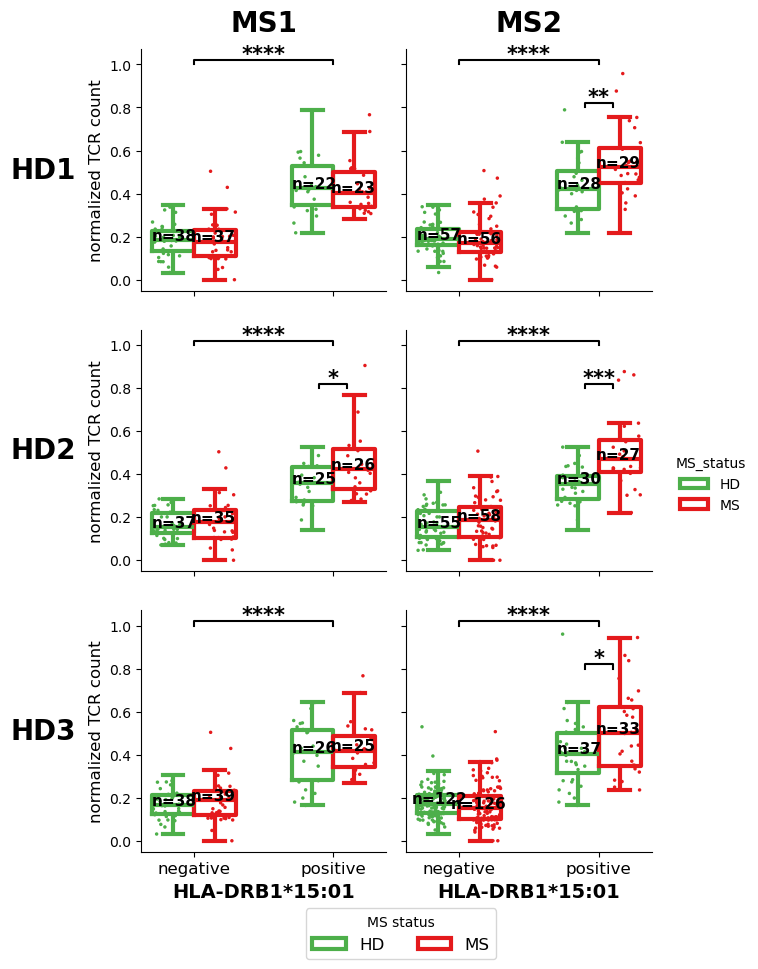

In [2]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


def annotate(data, **kws):
    
    x = data.groupby(['MS_datasets', 'HD_datasets']).size().index[0]
    p_pos = rslt_df.loc[f'{x}']['p_ms']
    p_hla = rslt_df.loc[f'{x}']['p_hla']
    
    star1 = convert_pvalue_to_asterisks(p_pos)
    # star2 = convert_pvalue_to_asterisks(p_neg)
    star3 = convert_pvalue_to_asterisks(p_hla)

    x1, x2 = 0, 1   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
    x3, x4 = -0.1, 0.1
    x5, x6 = 0.9, 1.1
    # y1, h, col = final_df['normalized_seqs'].max() + (final_df['normalized_seqs'].max() / 6), final_df['normalized_seqs'].max() / 30, 'k'
    # y2 = final_df['normalized_seqs'].max() + (final_df['normalized_seqs'].max() / 12)
    y1, h, col, y2 = 1.0, final_df['normalized_seqs'].max() / 50, 'k', 0.8

    if star3 != 'ns':
        plt.plot([x1, x1, x2, x2], [y1, y1+h, y1+h, y1], lw=1.5, c=col)
        plt.text((x1+x2)*.5, y1, f"{star3}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_hla,3)} 
    if star1 != 'ns':
        plt.plot([x5, x5, x6, x6], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
        plt.text((x5+x6)*.5, y2, f"{star1}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_pos, 3)} 
    # if star2 != 'ns':
    #     plt.plot([x3, x3, x4, x4], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
    #     plt.text((x3+x4)*.5, y2, f"{star2}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_neg, 3)} 
    
    x_labels = ['negative', 'positive']
    x_ticks = [0, 1]
    i=0
    # Print x-tick positions and corresponding labels
    for label, tick in zip(x_labels, x_ticks):
        min_df = data[data['HLA'] == label]

        df1 = min_df[min_df['MS_status'] == 'HD']
        df2 = min_df[min_df['MS_status'] == 'MS']
        num_hd = len(df1)
        num_ms = len(df2)

        plt.text(i-0.14, df1['normalized_seqs'].median(), f'n={num_hd}',ha="center", fontsize=11, fontweight='bold')
        plt.text(i+0.14, df2['normalized_seqs'].median(), f'n={num_ms}',ha="center", fontsize=11, fontweight='bold')

        i += 1
    plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
    plt.ylabel('normalized TCR count', fontsize=12) #, fontweight='bold'

    
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat

ms_datasets = ['ms01', 'ms03']
hd_datasets = ['hd01', 'hd02', 'microhd']

final_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'../subject_list/{ms_dataset}_{hd_dataset}.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()
        hla_df1 = pd.read_csv(f'../../meta_data_new_db/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]

        hla_df2 = pd.read_csv(f'../../meta_data_new_db/{hd_dataset}_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]

        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']

        df1 = pd.read_csv(f'./tables/{ms_dataset}.tsv', sep='\t')
        df1['normalized_seqs'] = df1.apply(lambda x: (x.unique_specific_sequences / x.unique_productive_rearrangment* 10000), axis=1) # 
        df2 = pd.read_csv(f'./tables/{hd_dataset}.tsv', sep='\t')
        df2['normalized_seqs'] = df2.apply(lambda x: (x.unique_specific_sequences / x.unique_productive_rearrangment* 10000), axis=1) # 
        df = pd.concat([df1, df2], ignore_index=True, sort=False)

        fig_df = df.merge(hla_df, on ='subject_id')
        fig_df = fig_df[fig_df['subject_id'].isin(subject_list)].drop_duplicates()

        fig_df['HD_datasets'] = f'{hd_dataset}'
        fig_df['MS_datasets'] = f'{ms_dataset}'
        final_df = pd.concat([final_df, fig_df], ignore_index=True, sort=False)
        
final_df['MS_status'] = final_df['MS_status'].map({'MS': 1, 'HD': 0})
# final_df = final_df[final_df['normalized_seqs'] != 0]
# final_df['normalized_seqs'] = np.where((final_df.normalized_seqs)!= 0, np.log(final_df.normalized_seqs),0)
# final_df['normalized_seqs'] = np.log1p(final_df.normalized_seqs)

cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

rslt_df = pd.DataFrame()
for dataset, sub_df1 in final_df.groupby(['MS_datasets', 'HD_datasets']):
    sub_df = sub_df1.iloc[:,1: 6]
    hla_pos = sub_df[sub_df['HLA'] == 1]
    hla_neg = sub_df[sub_df['HLA'] == 0]
    stats_hla, p_hla = mannwhitneyu(hla_pos['normalized_seqs'], hla_neg['normalized_seqs'], alternative='greater')

    ms = hla_pos[hla_pos['MS_status'] == 1]
    hd = hla_pos[hla_pos['MS_status'] == 0]
    stats_ms, p_ms = mannwhitneyu(ms['normalized_seqs'], hd['normalized_seqs'], alternative='greater')
    
    model = ({
        'datasets': [f'{dataset}'],
        'p_ms': [p_ms],
        'p_hla': [p_hla]
    })

    model_df = pd.DataFrame(model)
    rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('microhd', 'hd3')
rslt_df = rslt_df.set_index('datasets')

final_df["MS_status"] = final_df["MS_status"].map({0: "HD", 1: "MS"})
final_df['HLA'] = final_df['HLA'].map({0: 'negative', 1: 'positive'})
final_df['MS_datasets'] = final_df['MS_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('microhd', 'hd3')

hue_order = ['HD', 'MS']
g = sns.catplot(x="HLA", y="normalized_seqs", hue="MS_status", hue_order=hue_order,
                col='MS_datasets', row='HD_datasets', order=['negative', 'positive'], palette=cmap, legend=True,height=3, aspect=1,
                data=final_df, kind='box', showfliers = False, fill=False, boxprops=dict(linewidth=3), whiskerprops=dict(linewidth=3),
            capprops=dict(linewidth=3), medianprops=dict(linewidth=3), width=0.6)
g.map(sns.stripplot, "HLA", "normalized_seqs", 'MS_status', palette=cmap,
      hue_order=hue_order, jitter=0.2, order=['negative', 'positive'],
      size=2.5, dodge=True, legend=False)
g.map_dataframe(annotate)
# g.set_titles(('{row_name}' ' vs. ' '{col_name}'), size=18, weight='bold')
g.set_titles("")

for ax, row_name in zip(g.axes[:, 0], g.row_names):
    ax.annotate(row_name.upper(), xy=(-0.4, 0.5), xycoords=ax.transAxes, 
                va='center', ha='center', fontsize=20, weight='bold')

for ax, col_name in zip(g.axes[0], g.col_names):
    if col_name == 'ms3':
        col_name = 'ms2'
    else: col_name = col_name
    ax.set_title(col_name.upper(), fontsize=20, weight='bold', y=1.04)

for ax in g.axes.flat:
    ax.tick_params(axis='x',  labelsize=12)

plt.legend(bbox_to_anchor=(0.4, -0.2), fontsize=12, ncol=2, title='MS status')


# plt.setp(g.legend.texts, fontsize='16')
# plt.setp(g.legend.get_title(), fontsize='16')

# figUre_name = os.path.join('E:/Document/2024/06_18_review_untreated_samples/validation/boxplots/', f'{hla_name}.png')
# plt.savefig(figUre_name, bbox_inches='tight')
plt.show()
plt.close()

In [13]:
g.savefig('C:/Users/lynda/Desktop/Figures/Fig3/myimage2.png', format='png', dpi=600, bbox_inches='tight')

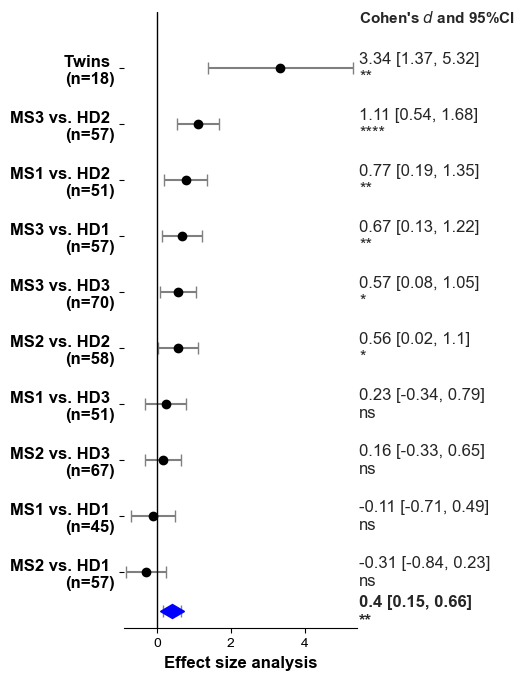

In [6]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import pingouin as pg
    
import statsmodels.api as sm
from scipy.stats import mannwhitneyu, wilcoxon

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as lines
from matplotlib.markers import MarkerStyle


def myfunc(string):
    if 'MS' in string:
        x = 'MS'
    else: x = 'HD'
    return x

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'

ms_datasets = ['ms01', 'ms02', 'ms03'] # 'ms02',
hd_datasets = ['hd01', 'hd02', 'microhd']

twins_df = pd.read_csv('./tables/twins.tsv', sep='\t')
twin_hla = pd.read_csv('F:/backup_E/meta_data/twins_hla_typing.tsv', sep='\t')
twins_df = twins_df.merge(twin_hla,on='subject_id')
twins_df = twins_df[twins_df['HLA_DRB1*15:01'] == 1]
twins_df['normalized_seqs'] = twins_df.apply(lambda x: (x.unique_specific_sequences / x.unique_productive_rearrangment)* 10000, axis=1)
twins_df['MS_status'] = twins_df.subject_id.apply(lambda x: myfunc(x))
df1 = twins_df[twins_df['MS_status'] == 'MS']
df2 = twins_df[twins_df['MS_status'] == 'HD']
statis, p_value = wilcoxon(df1['normalized_seqs'], df2['normalized_seqs'], alternative='greater')
# twins_df['MS_status'] = twins_df['MS_status'].map({'HD': 1, 'MS': 0})  # binary for regression

nx = len(df1)
ny = len(df2)
stat = pg.compute_effsize(df1['normalized_seqs'], df2['normalized_seqs'], paired=True, eftype='cohen')
ci = pg.compute_esci(stat=stat, nx=nx, ny=ny, paired=True, eftype='cohen')

model2 = ({
    'groups': ['Twins'],
    'r': [round(stat, 5)],
    'll': [round(ci[0], 5)],
    'hl': [round(ci[1], 5)],
    'n': [len(twins_df)],
    'pval': [round(p_value, 3)]
})
twins_df = pd.DataFrame(model2)
    
rslt_df = pd.DataFrame()
all_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'F:/backup_E/meta_data/subject_list/hla_balanced/{ms_dataset}_{hd_dataset}.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()
    
        hla_df1 = pd.read_csv(f'F:/backup_E/meta_data/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]
    
        hla_df2 = pd.read_csv(f'../../meta_data/{hd_dataset}_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]
    
        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']
    
        ms_df = pd.read_csv(f'./tables/{ms_dataset}.tsv', sep='\t')
        hd_df = pd.read_csv(f'./tables/{hd_dataset}.tsv', sep='\t')
        
        df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
    
        df = df.merge(hla_df, on ='subject_id')
        df = df[df['subject_id'].isin(subject_list)]
        df = df[df['HLA'] == 1]
        
        df['normalized_seqs'] = df.apply(lambda x: (x.unique_specific_sequences / x.unique_productive_rearrangment)* 10000, axis=1)
        df['MS_status'] = df.subject_id.apply(lambda x: myfunc(x))
        df = df[df['subject_id'].isin(subject_list)]
        df1 = df[df['MS_status'] == 'MS']
        df2 = df[df['MS_status'] == 'HD']
        statis, p_value = mannwhitneyu(df1['normalized_seqs'], df2['normalized_seqs'], alternative='greater')
    #         star = convert_pvalue_to_asterisks(p_value)
    
    #         df['MS_status'] = df['MS_status'].map({'HD': 1, 'MS': 0})  # binary for regression
        all_df = pd.concat([all_df, df], ignore_index=True, sort=False)
    
        nx = len(df1)
        ny = len(df2)
    
    #         df['MS_status'] = df['MS_status'].map({'HD': 1, 'MS': 0})  # binary for regression
    
        stat = pg.compute_effsize(df1['normalized_seqs'], df2['normalized_seqs'], paired=False, eftype='cohen')
        ci = pg.compute_esci(stat=stat, nx=nx, ny=ny, paired=False, eftype='cohen')
    #         p1 = pg.mwu(df1['percentage_vj'], df2['percentage_vj'], alternative='greater')['p-val'].values[0]
        
        model = ({
            'groups': [f'{ms_dataset.upper()}_{hd_dataset.upper()}'],
            'r': [round(stat, 5)],
            'll': [round(ci[0], 5)],
            'hl': [round(ci[1], 5)],
            'n': [len(df)],
            'pval': [round(p_value, 3)]
    #             'p1': [round(p1, 3)]
        })
    
        model_df = pd.DataFrame(model)
        rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

rslt_df = pd.concat([rslt_df, twins_df], ignore_index=True, sort=False)
rslt_df['groups'] = rslt_df['groups'].str.replace('_', ' vs. ')
rslt_df['groups'] = rslt_df['groups'].str.replace('0', '')
# rslt_df['groups'] = rslt_df['groups'].str.replace('MS3', 'MS2')
rslt_df['groups'] = rslt_df['groups'].str.replace('MICROHD', 'HD3')

data = rslt_df.sort_values(['r']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(3,8))
sns.set_style("whitegrid")
y_pos = np.arange(len(data))

# Plot error bars for individual groups
for i in range(len(data)):  # exclude last row (Overall)
    ax.errorbar(data['r'][i], y_pos[i],
                xerr=[[data['r'][i] - data['ll'][i]], 
                      [data['hl'][i] - data['r'][i]]],
                fmt='o', color='black', ecolor='gray', capsize=4)

all_df = all_df.drop_duplicates()
df1 = all_df[all_df['MS_status'] == 'MS']
df2 = all_df[all_df['MS_status'] == 'HD']
nx = len(df1)
ny = len(df2)

stat = pg.compute_effsize(df1['normalized_seqs'], df2['normalized_seqs'], paired=False, eftype='cohen')
ci = pg.compute_esci(stat=stat, nx=nx, ny=ny, paired=False, eftype='cohen')
p_all = pg.mwu(df1['normalized_seqs'], df2['normalized_seqs'], alternative='greater')['p-val'].values[0]
star = convert_pvalue_to_asterisks(p_all)

m = MarkerStyle("d")
m._transform.rotate_deg(90)
ax.errorbar(stat, -0.7, 
             xerr=[[stat - ci[0]], 
                   [ci[1] - stat]],
             color='blue', marker=m, ecolor='gray', 
             capsize=4, markersize=12)  # , marker=m, markersize=18, markerfacecolor="None"
ax.text(data.hl.max()+0.16, -0.7, f"{round(stat, 2)} {ci.tolist()} \n{star}", va='center', fontweight='bold', fontsize=12)

labels = [f"{row['groups']} \n(n={row['n']})" for _, row in data.iterrows()]
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontweight='bold', fontsize=12)

# for i, p in enumerate(data['pval']):
#     star = convert_pvalue_to_asterisks(p)
#     if p < 0.05: 
#         ax.text(data.hl.max()+0.12, y_pos[i], f"\n{star}", va='center', fontsize=12) # fontweight='bold',

i = 0
for r, ll, hl, p in zip(data['r'], data['ll'], data['hl'], data['pval']):
    star = convert_pvalue_to_asterisks(p)
    ax.text(data.hl.max()+0.16, y_pos[i], f"{round(r, 2)} [{ll}, {hl}] \n{star}", va='center', fontsize=12)
    i += 1

ax.text(data.hl.max()+0.16, len(data)-0.1, "Cohen's $d$ and 95%CI", va='center', fontsize=11, fontweight='bold')

ax.axvline(0, color='black', linewidth=1)

# Axis formatting
ax.set_xlabel("Effect size analysis", fontsize=12, fontweight='bold')
ax.set_xlim(min(data['ll']) - 0.05, max(data['hl']) + 0.1)
ax.set_ylim(-1, len(data))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
# ax.set_title("Effect size analysis", fontsize=16)

# Clean layout
# plt.tight_layout()
plt.show()
plt.close()